# What should a film studio greenlight?
DAO2702X group project: the analysis behind the report.

**Contents**

- Objective
- 1\. Data
    - 1.1 Raw files
    - 1.2 Parse and join
- 2\. Split
- 3\. Exploration
    - 3.1 Dataset checks
    - 3.2 The target
    - 3.3 Budget and risk
    - 3.4 Genre
    - 3.5 Release timing and competition
    - 3.6 Talent track record
    - 3.7 Studios
    - What the exploration found

## Objective

A studio decides before filming how much to spend, on what kind of film, with which director and lead, and when to release it. This notebook asks which of those choices change what a film earns per dollar and how often it loses money, so a studio can pick films, and a slate of films, that fit the risk it can carry.

Each row is one film. The inputs are only what is known before release: budget, genre, story source, production method, rating, runtime, release date, the competition around that date, and the director's and lead actor's earlier films. IMDb ratings, Facebook likes and opening-weekend figures are known only after release, so they are never inputs.

There are two targets, because a studio cares about the average return and about how often it loses money:

| Target | Definition | Meaning |
|---|---|---|
| `gross_multiple` | worldwide gross / production budget | 3.0 means the film took in three dollars at the box office for every dollar it cost to make |
| `flop` | `gross_multiple` < 2.5 | the film did not earn back its costs |

The 2.5 break-even line is an assumption. The studio keeps about half of the box office and the cinemas keep the rest, and marketing costs roughly another half of the production budget. A film that costs 100 to make ends up costing about 150 in total and needs about 300 at the box office, 3 times its budget, to cover it. Rules of thumb in the trade press run from 2 to 3 times the budget, and 2.5 sits in the middle. Later sections check that the main results hold at 2 and 3.

The model is built to explain: one linear regression on the log of the multiple, whose coefficients say how much each choice moves the return, and whose spread of errors gives the chance of a flop. Its predictions then feed a simulation of film slates, so a big studio and a small one can each pick the slate that fits their risk.

Import the libraries and the project's own tools, and set the shared chart style.

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
from plotnine import (
    aes,
    coord_flip,
    element_text,
    facet_wrap,
    geom_abline,
    geom_boxplot,
    geom_histogram,
    geom_hline,
    geom_line,
    geom_point,
    geom_text,
    geom_tile,
    geom_violin,
    geom_vline,
    ggplot,
    labs,
    scale_color_identity,
    scale_color_manual,
    scale_fill_gradientn,
    scale_fill_manual,
    scale_size,
    scale_x_log10,
    scale_y_log10,
    theme,
    theme_minimal,
    theme_set,
)

from lib.data_schemas import BREAK_EVEN_MULTIPLE, Film
from lib.features import count_competitors, prior_track_record
from lib.parsing import attach_closest_year, fix_mojibake, major_studio, title_key

RAW = Path("data/raw")

# one palette for every chart: blue marks the group under discussion, grey is context, red is the break-even line
ACCENT = "#2a78d6"
CONTEXT = "#b4b2ab"
FLOP_RED = "#e34948"
# budget tiers from cheapest to most expensive, light to dark blue
TIER_COLOURS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

# legend on top: a legend on the right sits past the pane edge when the plot is wide
theme_set(
    theme_minimal()
    + theme(
        figure_size=(10, 4.5),
        legend_position="top",
        plot_title=element_text(size=12, weight="bold"),
        text=element_text(color="#0b0b0b"),
    )
)
# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)

## 1. Data

### 1.1 Raw files

| File | Rows | What it gives this project |
|---|---|---|
| `movie_data.csv` | 3,647 films | the course dataset: genres, runtime, rating, country, director, lead actors, US gross |
| `the_numbers/movie-budgets.csv` | 5,460 films | The Numbers, scraped December 2019: US release date, production budget in USD, domestic and worldwide gross, story source, production method |
| `tmdb/tmdb_5000_movies.csv` | 4,803 films | TMDB: release date, budget, worldwide revenue, production companies |
| `fred/CPIAUCSL.csv` | monthly, 1947 on | US consumer price index, to put budgets from different years in 2016 dollars |

The course dataset is the base table, since it holds the genres and the people. It has two gaps the others fill. Its `gross` is the US box office only, and its budgets for non-US films are in the local currency (*The Host* shows 12,215, in millions of won). So worldwide gross and the budget in dollars come from The Numbers, or from TMDB where The Numbers has no match.

### 1.2 Parse and join

Fixes made while reading, none of which depend on the values:

- text that was saved in the wrong encoding is decoded again (`PenÃ©lope` becomes `Penélope`), and stray spaces are trimmed
- money strings such as `$400,000,000` become numbers, and dates such as `Apr 23, 2019` become dates
- a budget or revenue of 0 in TMDB means unknown, so it becomes null
- in about 300 rows of The Numbers the scrape shifted columns, leaving text such as "All Time Domestic Box Office for..." in the story source or production method; those cells become null
- 42 films appear twice in the course dataset with the same title, year and director; one copy is kept
- films released before 1947 are dropped, since the price index starts that year
- titles are matched through `title_key`, the title in lowercase letters and digits with "the" dropped, and a match must be within one year, since sources sometimes date a film by its festival premiere

Read the course dataset and keep the columns the analysis uses.

In [2]:
base = (
    pl.read_csv(RAW / "movie_data.csv", infer_schema_length=None, encoding="utf8-lossy")
    .select(
        pl.col("movie_title").alias("title"),
        "genres",
        pl.col("duration").alias("duration_min"),
        "country",
        "content_rating",
        pl.col("title_year").alias("year"),
        pl.col("director_name").alias("director"),
        pl.col("actor_1_name").alias("actor_1"),
        (pl.col("gross") * 1e6).alias("base_us_gross_usd"),
    )
    .with_columns(
        pl.col("title", "director", "actor_1", "country")
        .map_elements(fix_mojibake, return_dtype=pl.String)
        .str.strip_chars()
    )
    .unique(["title", "year", "director"], keep="first", maintain_order=True)
    .with_row_index("film_id")
    .with_columns(
        title_key=pl.col("title").map_elements(title_key, return_dtype=pl.String)
    )
)
base.shape

(3627, 11)

Read The Numbers, turning money and dates into numbers and clearing the shifted cells.

In [3]:
dollars = lambda column: (
    pl.col(column).str.replace_all(r"[$,]", "").cast(pl.Float64, strict=False)
)
shifted = lambda column: (
    pl.when(pl.col(column).str.starts_with("All Time"))
    .then(None)
    .otherwise(pl.col(column))
)

the_numbers = (
    pl.read_csv(
        RAW / "the_numbers/movie-budgets.csv",
        infer_schema_length=None,
        encoding="utf8-lossy",
    )
    .with_columns(
        title_key=pl.col("title").map_elements(title_key, return_dtype=pl.String),
        numbers_release_date=pl.col("release_date").str.to_date(
            "%b %d, %Y", strict=False
        ),
        numbers_budget_usd=dollars("production_budget"),
        numbers_domestic_usd=dollars("domestic_gross"),
        numbers_worldwide_usd=dollars("worldwide_gross"),
        story_source=shifted("story_source"),
        production_method=shifted("production_method"),
    )
    .with_columns(year=pl.col("numbers_release_date").dt.year())
    .select(
        "title_key",
        "year",
        "numbers_release_date",
        "numbers_budget_usd",
        "numbers_domestic_usd",
        "numbers_worldwide_usd",
        "story_source",
        "production_method",
    )
    .unique(["title_key", "year"], keep="first", maintain_order=True)
)
the_numbers.shape

(5459, 8)

Read TMDB and name each film's major parent studio from its list of production companies (Independent when none of them is a major).

In [4]:
company_list = pl.List(pl.Struct({"name": pl.String, "id": pl.Int64}))

tmdb = (
    pl.read_csv(RAW / "tmdb/tmdb_5000_movies.csv", infer_schema_length=None)
    .with_columns(
        title_key=pl.col("title").map_elements(title_key, return_dtype=pl.String),
        tmdb_release_date=pl.col("release_date").str.to_date(strict=False),
        tmdb_budget_usd=pl.when(pl.col("budget") > 0).then(
            pl.col("budget").cast(pl.Float64)
        ),
        tmdb_worldwide_usd=pl.when(pl.col("revenue") > 0).then(
            pl.col("revenue").cast(pl.Float64)
        ),
        studio=pl.col("production_companies")
        .str.json_decode(company_list)
        .list.eval(pl.element().struct.field("name"))
        .map_elements(
            lambda companies: major_studio(list(companies)), return_dtype=pl.String
        ),
    )
    .with_columns(year=pl.col("tmdb_release_date").dt.year())
    .select(
        "title_key",
        "year",
        "tmdb_release_date",
        "tmdb_budget_usd",
        "tmdb_worldwide_usd",
        "studio",
    )
    .unique(["title_key", "year"], keep="first", maintain_order=True)
)
tmdb.shape

(4803, 6)

Average the monthly consumer price index to one value per year, as the factor that turns that year's dollars into 2016 dollars.

In [5]:
cpi = (
    pl.read_csv(RAW / "fred/CPIAUCSL.csv", try_parse_dates=True)
    .group_by(year=pl.col("observation_date").dt.year())
    .agg(pl.col("CPIAUCSL").mean().alias("cpi"))
)
cpi_2016 = cpi.filter(pl.col("year") == 2016).item(0, "cpi")
to_2016_dollars = cpi.select("year", (cpi_2016 / pl.col("cpi")).alias("to_2016_factor"))

Attach The Numbers and TMDB to the course dataset, take each money figure from the best source that has it, and compute the targets.

The Numbers comes first for the release date, budget and gross, since it tracks US releases and reports budgets in dollars; TMDB fills what it lacks. Each film's release year then replaces the course dataset's year, so the price factor and the split use the date the film reached cinemas.

In [6]:
joined = attach_closest_year(base, the_numbers, max_year_gap=1)
joined = attach_closest_year(joined, tmdb, max_year_gap=1)

films = (
    joined.with_columns(
        release_date=pl.coalesce("numbers_release_date", "tmdb_release_date"),
        budget_usd=pl.coalesce("numbers_budget_usd", "tmdb_budget_usd"),
        worldwide_gross_usd=pl.coalesce(
            pl.when(pl.col("numbers_worldwide_usd") > 0).then(
                pl.col("numbers_worldwide_usd")
            ),
            "tmdb_worldwide_usd",
        ),
        domestic_gross_usd=pl.coalesce("numbers_domestic_usd", "base_us_gross_usd"),
        studio=pl.col("studio").fill_null("Independent"),
    )
    .drop_nulls(["release_date", "budget_usd", "worldwide_gross_usd"])
    .with_columns(year=pl.col("release_date").dt.year())
    .join(to_2016_dollars, on="year", how="inner")
    .with_columns(
        budget_real_musd=pl.col("budget_usd") / 1e6 * pl.col("to_2016_factor"),
        worldwide_gross_real_musd=pl.col("worldwide_gross_usd")
        / 1e6
        * pl.col("to_2016_factor"),
        gross_multiple=pl.col("worldwide_gross_usd") / pl.col("budget_usd"),
    )
    .with_columns(
        log_multiple=pl.col("gross_multiple").log(),
        flop=pl.col("gross_multiple") < BREAK_EVEN_MULTIPLE,
    )
)
films = Film.validate(films)
films.shape

(3464, 22)

Count how many films each source supplied and how many dropped out.

In [7]:
pl.DataFrame(
    {
        "step": [
            "course dataset, after removing duplicates",
            "matched in The Numbers",
            "matched in TMDB",
            "matched in neither",
            "kept: release date, budget and worldwide gross known, released 1947 or later",
        ],
        "films": [
            base.height,
            joined["numbers_release_date"].is_not_null().sum(),
            joined["tmdb_release_date"].is_not_null().sum(),
            joined.filter(
                pl.col("numbers_release_date").is_null()
                & pl.col("tmdb_release_date").is_null()
            ).height,
            films.height,
        ],
    }
)

step,films
str,i64
"""course dataset, after removing duplicates""",3627
"""matched in The Numbers""",3315
"""matched in TMDB""",3559
"""matched in neither""",46
"""kept: release date, budget and worldwide gross known, releas…",3464


3,464 of the 3,627 films keep a release date, a dollar budget and a worldwide gross. 46 matched neither source; the other 117 lacked a budget or gross or came out before 1947.

## 2. Split

The studio always judges a new film from the films that came before it, so the split follows time. Three sets:

- `dev`: films released up to 2012, for exploration, choosing the model and cross-validation
- `test`: films released 2013 to 2015, scored once by the final model
- `reserve`: films released in 2016, a partial year since the course dataset stops there, scored once at the end as a bonus

Three test years rather than one, because one year holds only about 150 films, too few to read a flop rate from. From here on, everything that describes the values looks at `dev` only.

In [8]:
dev = films.filter(pl.col("year") <= 2012)
test = films.filter(pl.col("year").is_between(2013, 2015))
reserve = films.filter(pl.col("year") >= 2016)

pl.DataFrame(
    {
        "set": ["dev", "test", "reserve"],
        "films": [dev.height, test.height, reserve.height],
        "first_release": [
            frame["release_date"].min() for frame in (dev, test, reserve)
        ],
        "last_release": [frame["release_date"].max() for frame in (dev, test, reserve)],
    }
)

set,films,first_release,last_release
str,i64,date,date
"""dev""",2997,1948-05-20,2012-12-26
"""test""",408,2013-01-01,2015-12-31
"""reserve""",59,2016-01-04,2016-10-16


The three sets follow each other in time without overlap: `dev` covers 1948 to 2012, `test` 2013 to 2015, `reserve` January to October 2016.

## 3. Exploration

### 3.1 Dataset checks

Count films per decade and the share of each column that is missing.

In [9]:
dev.group_by(decade=(pl.col("year") // 10 * 10)).agg(
    pl.len().alias("films"),
    pl.col("flop").mean().alias("flop_share"),
).sort("decade")

decade,films,flop_share
i64,u32,f64
1940,1,1.000
1950,8,0.250
1960,24,0.167
1970,43,0.116
1980,191,0.387
1990,672,0.603
2000,1575,0.635
2010,483,0.563


Only 76 `dev` films came out before 1980, and only 16% of them flopped against 60% after. The sources keep old films that people still remember, which are mostly hits, so the early decades show survivors rather than what a studio could expect.

Show the share of missing values in every column that has any.

In [10]:
(
    dev.null_count()
    .transpose(include_header=True, header_name="column", column_names=["missing"])
    .filter(pl.col("missing") > 0)
    .with_columns(missing_share=pl.col("missing") / dev.height)
)

column,missing,missing_share
str,u32,f64
"""content_rating""",12,0.004
"""story_source""",341,0.114
"""production_method""",264,0.088


Three columns have gaps: story source for 11% of films, production method for 9%, content rating for 0.4%. Everything the targets need is complete.

### 3.2 The target

Plot the distribution of the gross multiple on a log scale, with the break-even line in red.

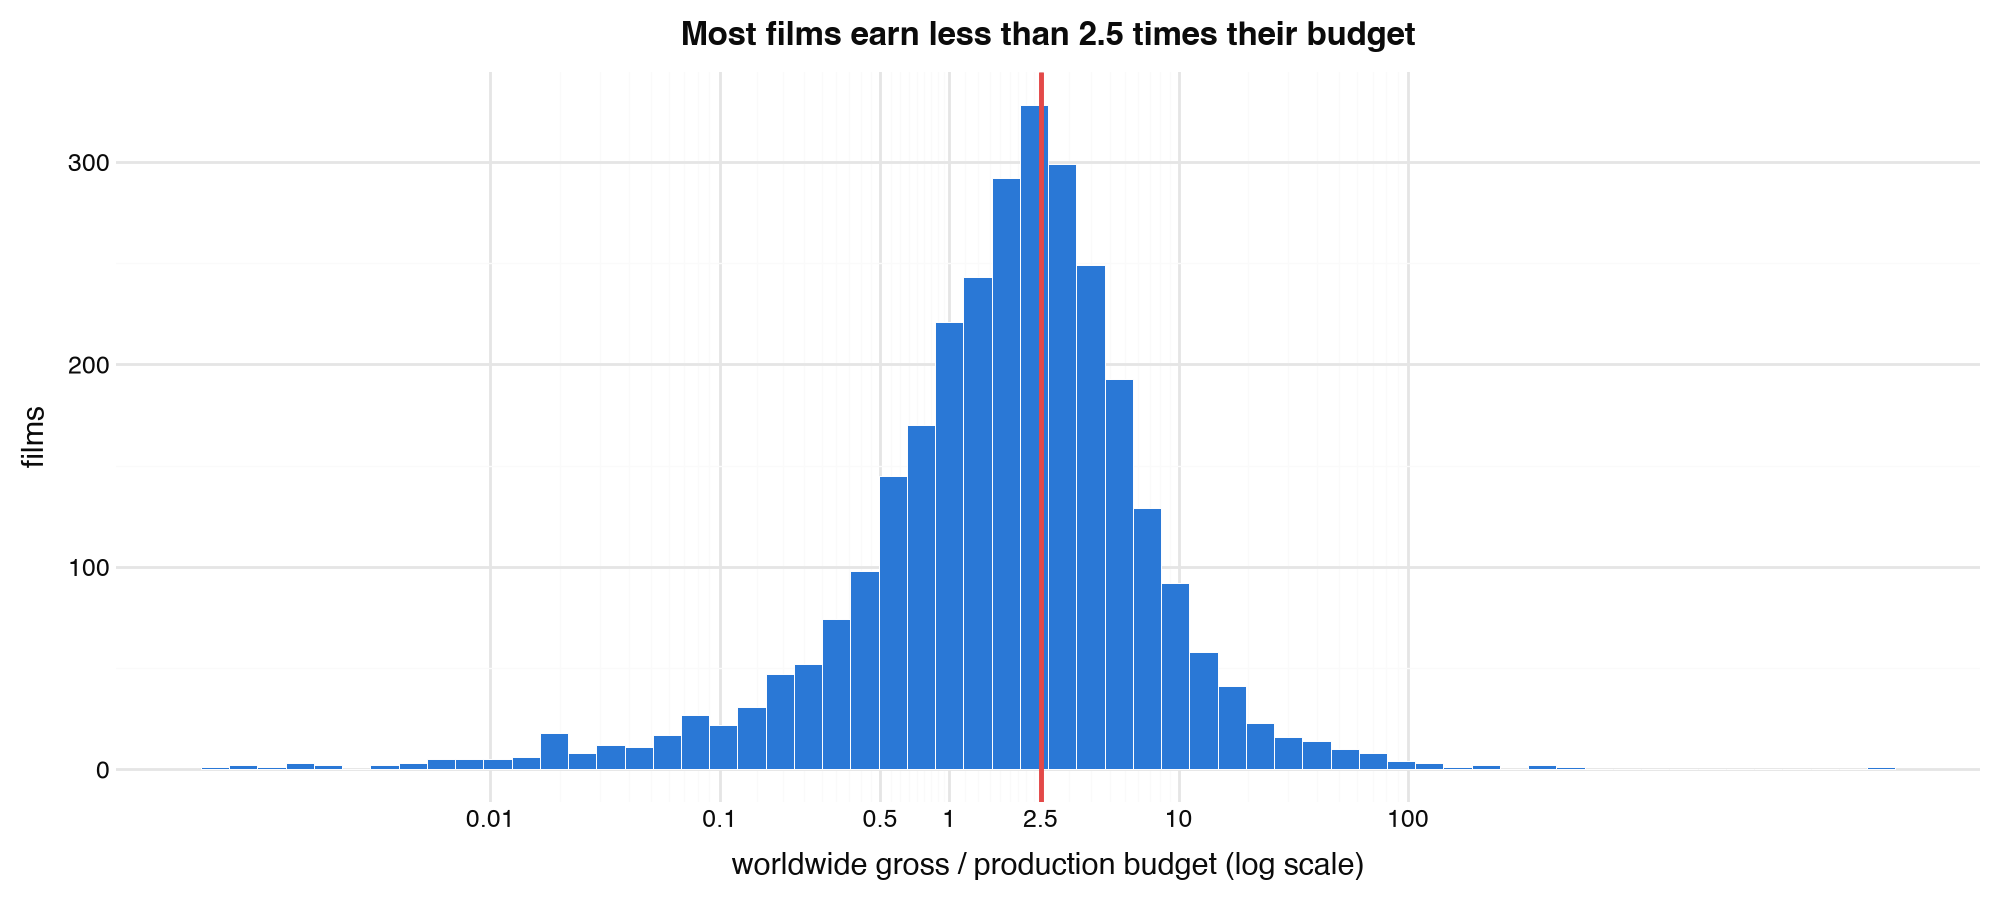

In [11]:
(
    ggplot(dev, aes("gross_multiple"))
    + geom_histogram(bins=60, fill=ACCENT, color="white", size=0.2)
    + geom_vline(xintercept=BREAK_EVEN_MULTIPLE, color=FLOP_RED, size=1)
    + scale_x_log10(breaks=[0.01, 0.1, 0.5, 1, 2.5, 10, 100])
    + labs(
        title="Most films earn less than 2.5 times their budget",
        x="worldwide gross / production budget (log scale)",
        y="films",
    )
)

Summarise the multiple and the flop share.

In [12]:
dev.select(
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("gross_multiple").quantile(0.1).alias("p10_multiple"),
    pl.col("gross_multiple").quantile(0.9).alias("p90_multiple"),
    pl.col("flop").mean().alias("flop_share"),
    (pl.col("gross_multiple") < 1).mean().alias("below_budget_share"),
    pl.col("log_multiple").std().alias("log_multiple_sd"),
)

median_multiple,p10_multiple,p90_multiple,flop_share,below_budget_share,log_multiple_sd
f64,f64,f64,f64,f64,f64
1.984,0.309,7.978,0.588,0.294,1.492


The median film took in 1.98 times its budget, 59% fell below the 2.5 break-even, and 29% did not take in even their budget. The top 10% earned nearly 8 times their budget or more and the bottom 10% less than 0.31 times.

On the log scale the multiple is roughly bell-shaped with a long left tail, which is why the model works on the log: a linear regression's errors are then close to symmetric. Its standard deviation of 1.49 means two films in three land between a quarter and 4.4 times the median multiple, so any single forecast will be rough.

### 3.3 Budget and risk

H1 says a bigger budget lowers the risk, not just raises the gross. Budgets are in 2016 dollars and cut into four tiers: under 20, 20 to 60, 60 to 120, and 120 million or more.

Plot worldwide gross against budget, both in 2016 dollars on log scales. The grey line marks gross equal to budget, the red line 2.5 times budget; films below the red line flopped.

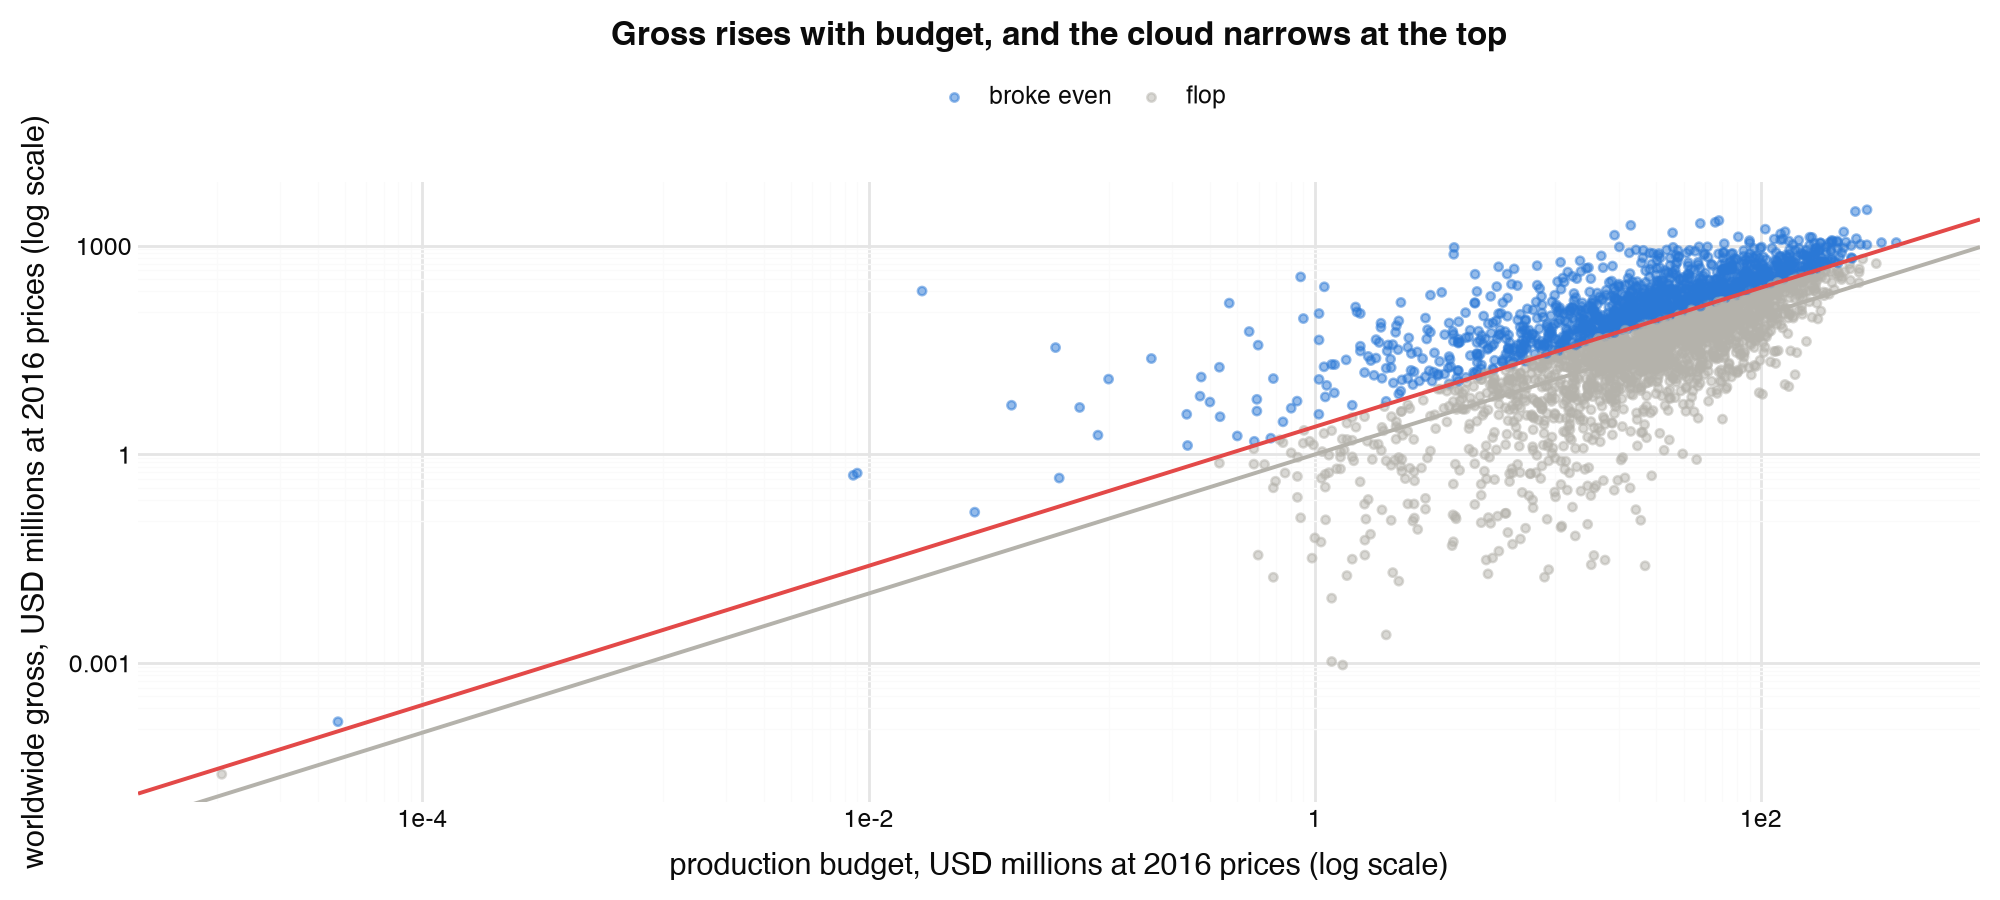

In [13]:
tiers = ["under 20M", "20-60M", "60-120M", "120M+"]
budget_tier = (
    pl.when(pl.col("budget_real_musd") < 20)
    .then(pl.lit(tiers[0]))
    .when(pl.col("budget_real_musd") < 60)
    .then(pl.lit(tiers[1]))
    .when(pl.col("budget_real_musd") < 120)
    .then(pl.lit(tiers[2]))
    .otherwise(pl.lit(tiers[3]))
    .cast(pl.Enum(tiers))
    .alias("budget_tier")
)
dev = dev.with_columns(
    budget_tier,
    outcome=pl.when(pl.col("flop"))
    .then(pl.lit("flop"))
    .otherwise(pl.lit("broke even")),
)

(
    ggplot(dev, aes("budget_real_musd", "worldwide_gross_real_musd"))
    + geom_point(aes(color="outcome"), size=1.2, alpha=0.5)
    + geom_abline(intercept=0, slope=1, color=CONTEXT, size=0.8)
    + geom_abline(
        intercept=np.log10(BREAK_EVEN_MULTIPLE), slope=1, color=FLOP_RED, size=0.8
    )
    + scale_x_log10()
    + scale_y_log10()
    + scale_color_manual(values={"flop": CONTEXT, "broke even": ACCENT})
    + labs(
        title="Gross rises with budget, and the cloud narrows at the top",
        x="production budget, USD millions at 2016 prices (log scale)",
        y="worldwide gross, USD millions at 2016 prices (log scale)",
        color="",
    )
)

Bigger budgets bring bigger grosses, and above about $100M almost every film lands within a factor of 10 of its budget, while films under $10M range from nearly nothing to over 100 times their cost. 55 films list a budget under $1M at 2016 prices, some of a few dollars, which can only be errors in the sources.

Compare the spread of the multiple across the four budget tiers.

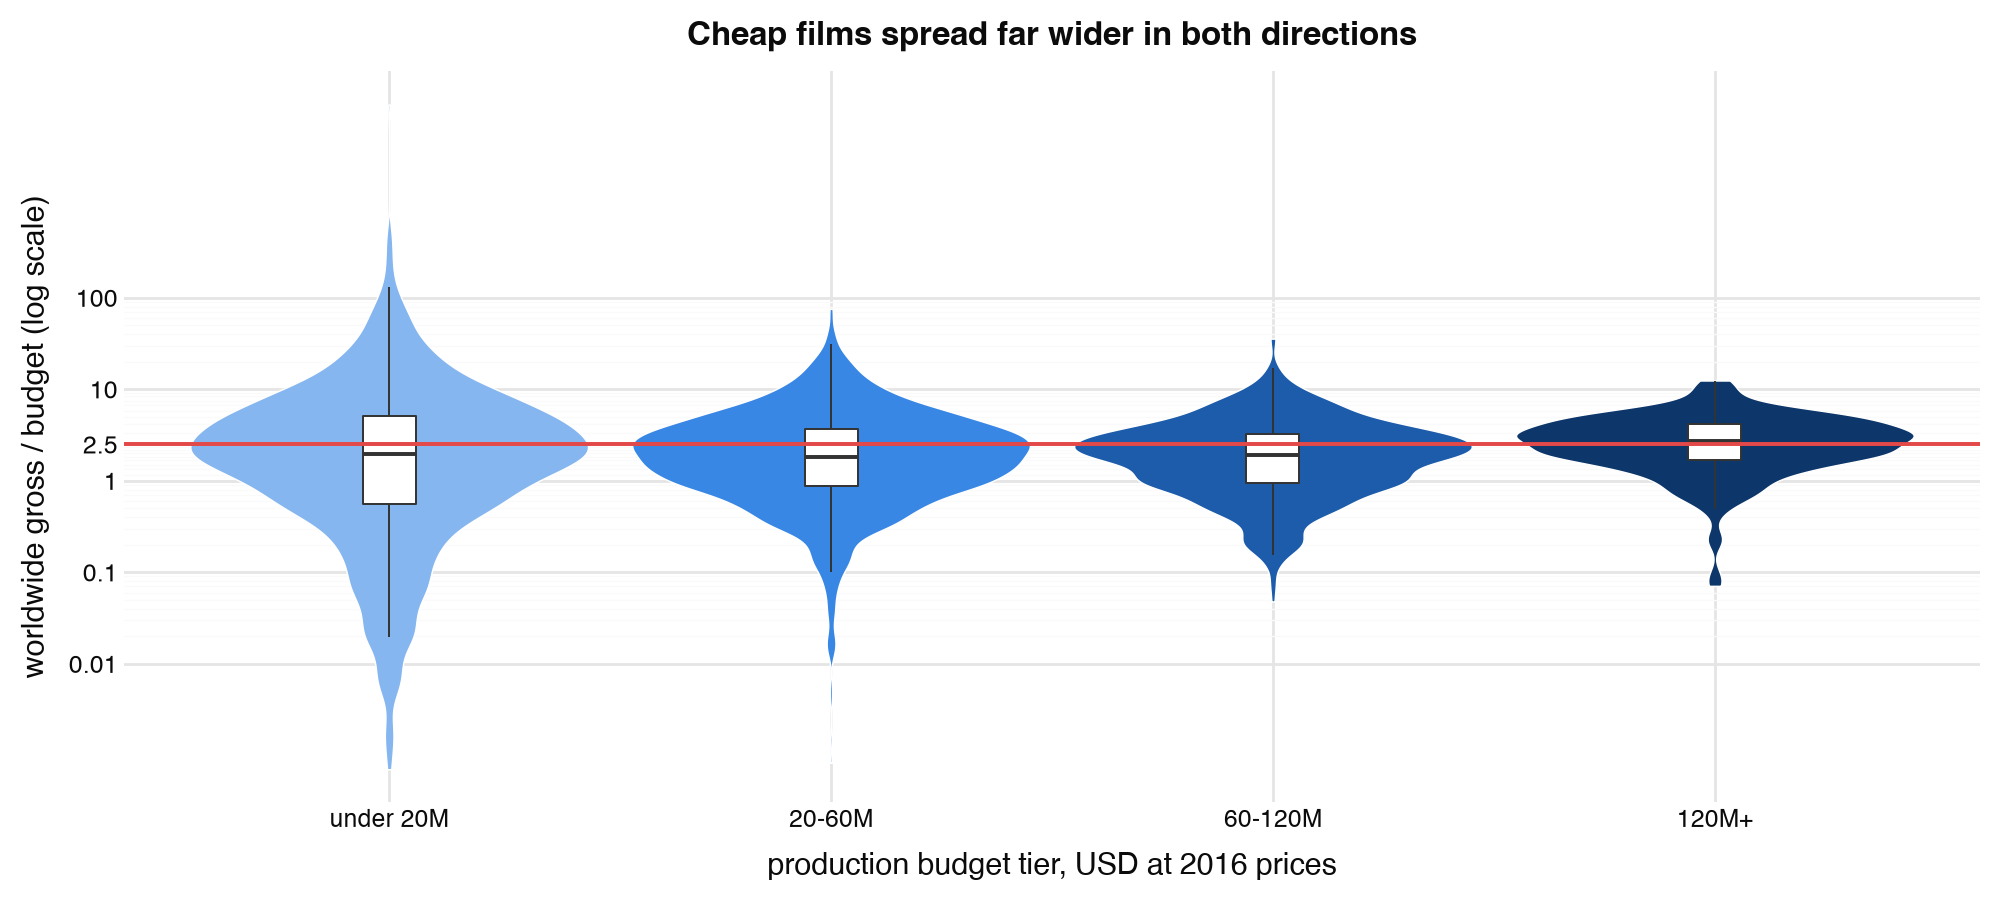

In [14]:
(
    ggplot(dev, aes("budget_tier", "gross_multiple", fill="budget_tier"))
    + geom_violin(color="white", size=0.3, scale="width")
    + geom_boxplot(width=0.12, fill="white", outlier_alpha=0, size=0.4)
    + geom_hline(yintercept=BREAK_EVEN_MULTIPLE, color=FLOP_RED, size=0.8)
    + scale_y_log10(breaks=[0.01, 0.1, 1, 2.5, 10, 100])
    + scale_fill_manual(values=TIER_COLOURS)
    + labs(
        title="Cheap films spread far wider in both directions",
        x="production budget tier, USD at 2016 prices",
        y="worldwide gross / budget (log scale)",
        fill="",
    )
    + theme(legend_position="none")
)

The medians sit close together while the range narrows steadily from the cheapest tier to the most expensive.

Summarise return and risk per tier. `p10_multiple` and `p90_multiple` are the multiples that 10% of films fall below and 10% rise above.

In [15]:
tier_summary = (
    dev.group_by("budget_tier")
    .agg(
        pl.len().alias("films"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("gross_multiple").quantile(0.1).alias("p10_multiple"),
        pl.col("gross_multiple").quantile(0.9).alias("p90_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .sort("budget_tier")
)
tier_summary

budget_tier,films,median_multiple,p10_multiple,p90_multiple,flop_share
enum,u32,f64,f64,f64,f64
"""under 20M""",967,1.964,0.090,13.608,0.576
"""20-60M""",1156,1.838,0.373,7.080,0.606
"""60-120M""",627,1.905,0.486,5.417,0.624
"""120M+""",247,2.682,0.951,5.458,0.466


Films over $120M are the only tier where most films break even: 47% flopped, against 58% to 62% in the cheaper tiers, and their worst 10% still took in 0.95 times their budget. Films under $20M have about the same median as the middle tiers (1.96) but the widest range: the bottom 10% took in less than 0.09 times their budget, the top 10% more than 13.6 times.

So H1 holds for risk: a big budget buys a narrower range far more than a higher median. The model needs the spread of its errors to depend on the budget, or it will give a $200M film the same flop chance as a $5M one.

### 3.4 Genre

H2 says romance is cheap and safe money. A film has up to eight IMDb genres, so it counts once in each; a romantic comedy is in both Romance and Comedy.

Summarise each genre's median multiple and flop share, for genres with at least 50 films.

In [16]:
by_genre = (
    dev.with_columns(genre=pl.col("genres").str.split("|"))
    .explode("genre", empty_as_null=True)
    .group_by("genre")
    .agg(
        pl.len().alias("films"),
        pl.col("budget_real_musd").median().alias("median_budget_musd"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .filter(pl.col("films") >= 50)
    .with_columns(
        highlight=pl.when(pl.col("genre").is_in(["Romance", "Horror"]))
        .then(pl.lit("yes"))
        .otherwise(pl.lit("no"))
    )
    .sort("median_multiple", descending=True)
)
by_genre

genre,films,median_budget_musd,median_multiple,flop_share,highlight
str,u32,f64,f64,f64,str
"""Animation""",143,89.306,2.793,0.455,"""no"""
"""Family""",358,58.260,2.550,0.494,"""no"""
"""Horror""",304,22.085,2.442,0.516,"""yes"""
"""Musical""",78,43.811,2.358,0.526,"""no"""
"""Adventure""",602,74.370,2.353,0.518,"""no"""
"""Music""",122,24.163,2.202,0.541,"""no"""
"""Mystery""",308,35.610,2.194,0.565,"""no"""
"""Fantasy""",390,57.930,2.152,0.569,"""no"""
"""Romance""",727,30.256,2.022,0.579,"""yes"""


Plot each genre's return against its flop share; bubble size is the number of films. Up and to the left is better: more return, fewer flops.

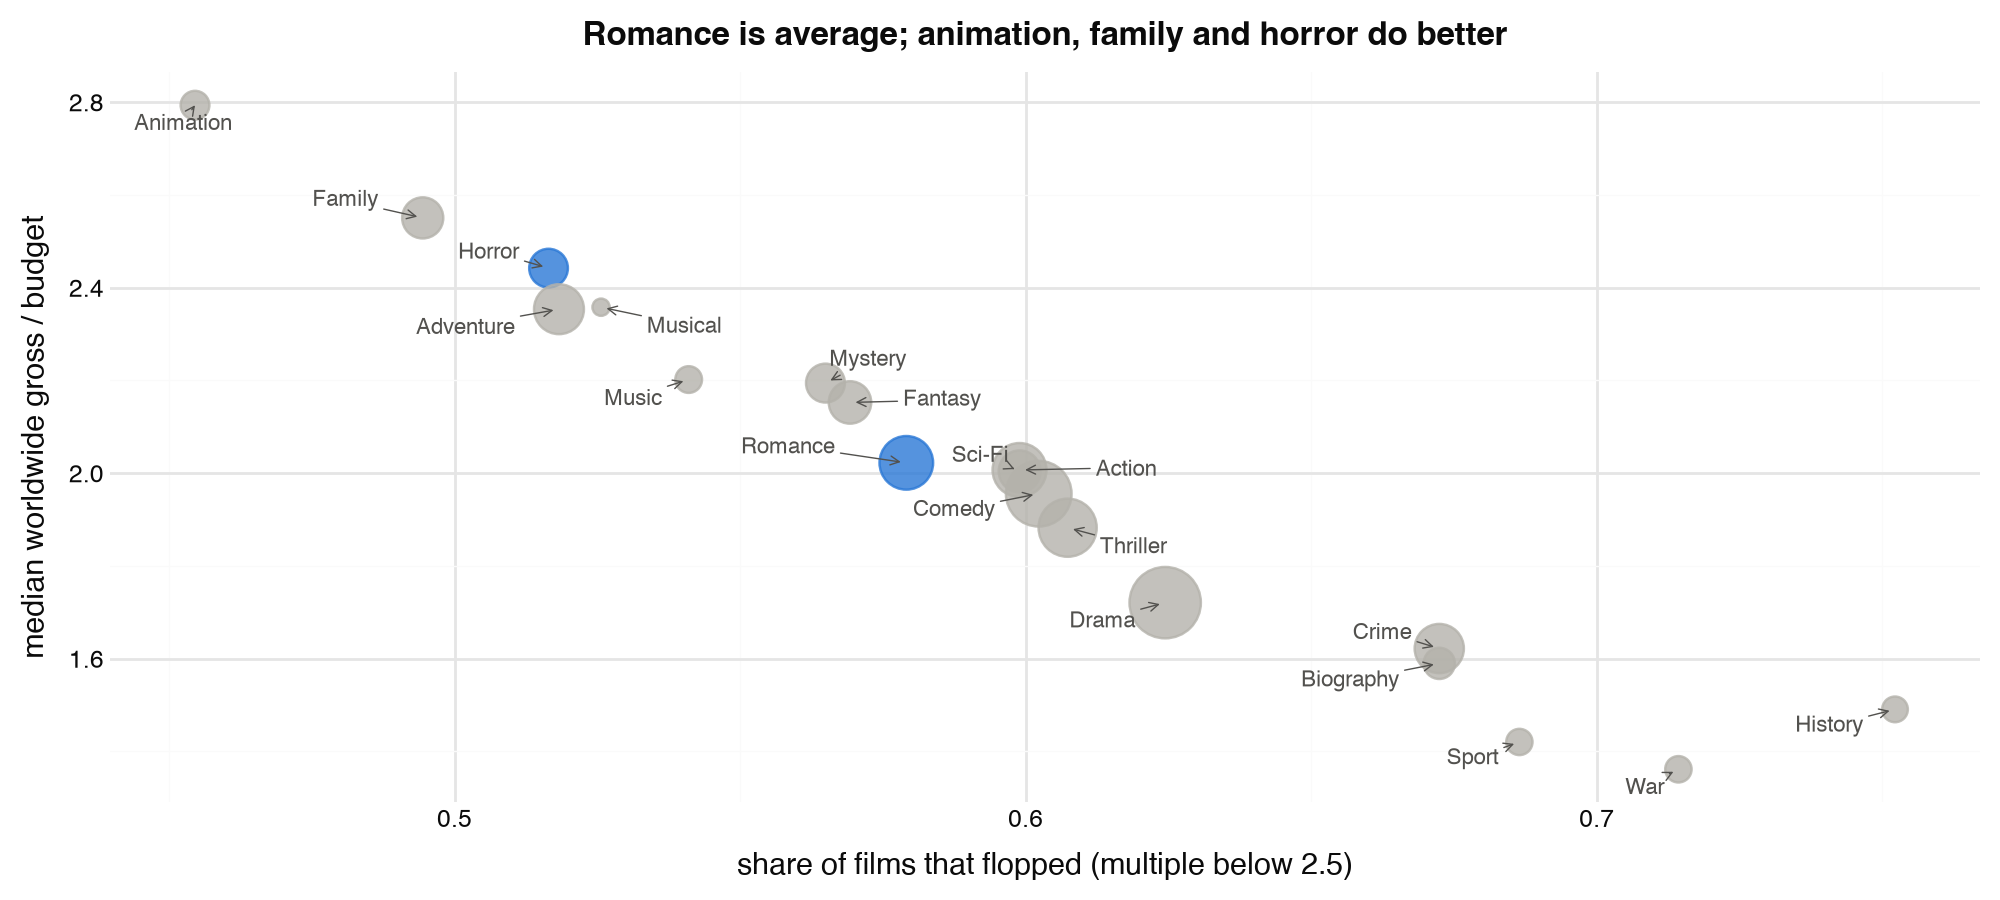

In [17]:
(
    ggplot(by_genre, aes("flop_share", "median_multiple"))
    + geom_point(aes(size="films", color="highlight"), alpha=0.8)
    + geom_text(
        aes(label="genre"), size=8, color="#52514e", adjust_text={"expand": (1.6, 1.8)}
    )
    + scale_size(range=(3, 14))
    + scale_color_manual(values={"yes": ACCENT, "no": CONTEXT})
    + labs(
        title="Romance is average; animation, family and horror do better",
        x="share of films that flopped (multiple below 2.5)",
        y="median worldwide gross / budget",
    )
    + theme(legend_position="none")
)

Romance sits in the middle: median 2.0 times budget and 58% flopped, next to Comedy and Action. Animation, Family and Horror return the most (2.4 to 2.8 times) and flop least (46% to 52%); War, Sport and History do worst (1.4 to 1.5 times, 69% to 75% flopped).

H2 fails for romance. The genres lie almost on one line, so a genre with a higher median also flops less often: genre moves the whole distribution rather than trading return against risk.

Horror is the cheapest genre here, so part of its edge may only be the budget-tier effect from 3.3. Show the flop share for each genre within each budget tier; cells with fewer than 15 films are left blank.

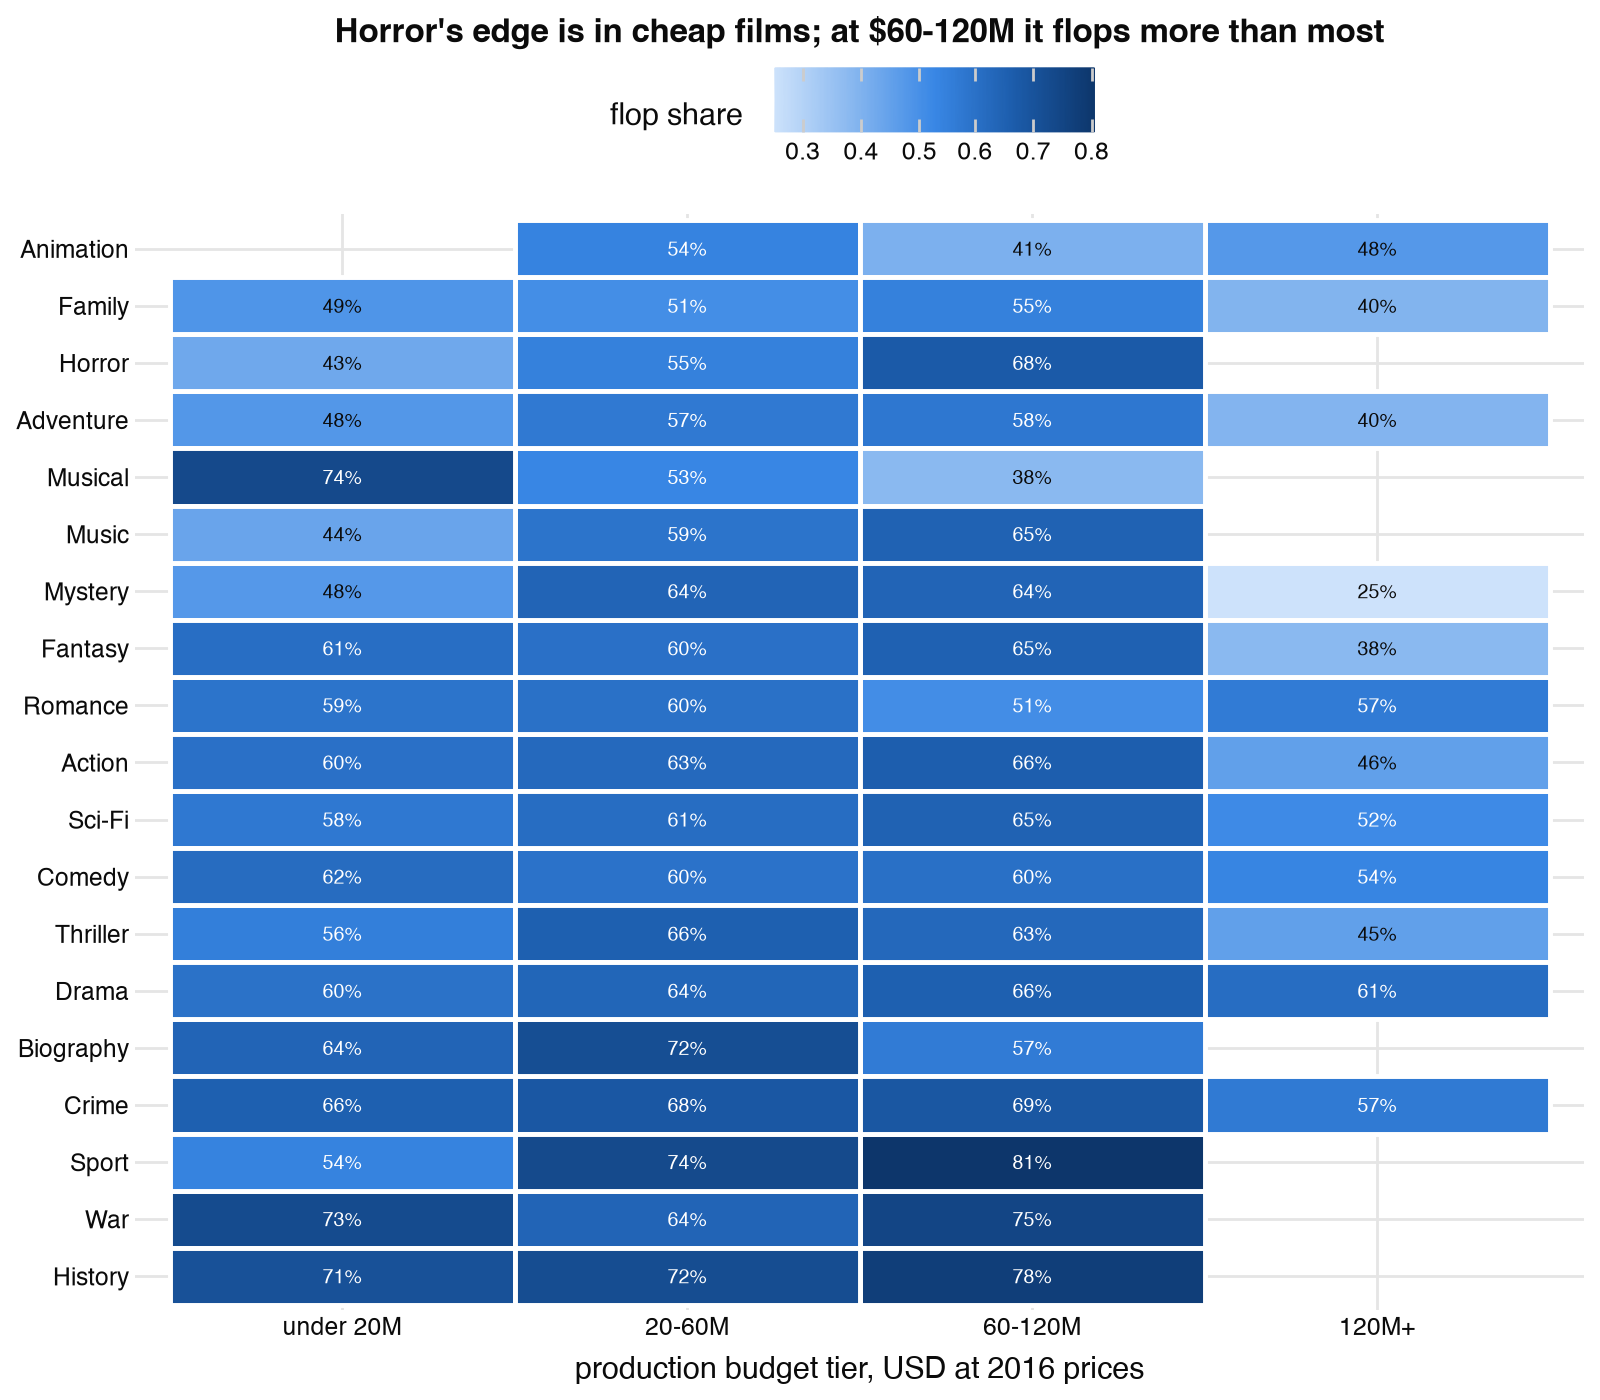

In [18]:
genre_by_tier = (
    dev.with_columns(genre=pl.col("genres").str.split("|"))
    .explode("genre", empty_as_null=True)
    .filter(pl.col("genre").is_in(by_genre["genre"].to_list()))
    .group_by("genre", "budget_tier")
    .agg(pl.len().alias("films"), pl.col("flop").mean().alias("flop_share"))
    .filter(pl.col("films") >= 15)
    .with_columns(
        # genres ordered by their overall flop share, safest at the top
        pl.col("genre").cast(
            pl.Enum(by_genre.sort("flop_share", descending=True)["genre"].to_list())
        ),
        label=(pl.col("flop_share") * 100).round(0).cast(pl.Int64).cast(pl.String)
        + "%",
        # dark text on the light cells, white on the dark ones
        text_colour=pl.when(pl.col("flop_share") < 0.5)
        .then(pl.lit("#0b0b0b"))
        .otherwise(pl.lit("white")),
    )
)

(
    ggplot(genre_by_tier, aes("budget_tier", "genre", fill="flop_share"))
    + geom_tile(color="white", size=1)
    + geom_text(aes(label="label", color="text_colour"), size=7)
    + scale_color_identity()
    + scale_fill_gradientn(
        colors=["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
    )
    + labs(
        title="Horror's edge is in cheap films; at $60-120M it flops more than most",
        x="production budget tier, USD at 2016 prices",
        y="",
        fill="flop share",
    )
    + theme(figure_size=(8, 7))
)

Inside one budget tier the genre gaps shrink and sometimes flip. Horror under $20M flops 43% of the time, the lowest in that tier, but horror at $60-120M flops 68%. Romance stays between 51% and 60% in every tier.

So the best genre depends on how much is spent. A model with genre and budget as separate terms would credit expensive horror with the edge of cheap horror.

### 3.5 Release timing and competition

H3 says releasing into a crowded window cuts the return. Competition is counted from every release with a known date in The Numbers or TMDB (about 6,600 films), since a studio knows the release calendar when it picks its date:

- `competitors`: other films released within 30 days before or after
- `big_competitors`: those with a budget at least as large as the film's own
- `competitor_budget_musd`: their budgets added up, in USD millions

Build the calendar and count each film's competitors.

In [19]:
calendar = (
    pl.concat(
        [
            the_numbers.select(
                "title_key",
                "year",
                release_date="numbers_release_date",
                budget_usd="numbers_budget_usd",
            ),
            tmdb.select(
                "title_key",
                "year",
                release_date="tmdb_release_date",
                budget_usd="tmdb_budget_usd",
            ),
        ]
    )
    .drop_nulls("release_date")
    .unique(["title_key", "year"], keep="first", maintain_order=True)
)
competition = count_competitors(films, calendar, window_days=30)
dev = dev.join(competition, on="film_id", how="left")
calendar.height

6626

Show the median number of competitors per five-year period.

In [20]:
dev.group_by(period=pl.col("year") // 5 * 5).agg(
    pl.len().alias("films"),
    pl.col("competitors").median().alias("median_competitors"),
).sort("period")

period,films,median_competitors
i64,u32,f64
1945,1,0.000
1950,6,0.000
1955,2,0.500
1960,12,1.500
1965,12,1.000
1970,20,2.000
1975,23,3.000
1980,74,6.000
1985,117,6.000


The median film released after 2005 had 50 others within 30 days of it in the calendar, against 6 in the 1980s. The sources track recent films far more completely, so a raw count mostly measures the release year.

So competition is measured against the film's own year. `crowding` is the film's competitors divided by the median for films released the same year: 1.2 means 20% more films around its date than usual that year. Plot the median multiple by fifth of crowding, one line per budget tier so a cheap film is only compared with other cheap films. Points with fewer than 20 films are left out.

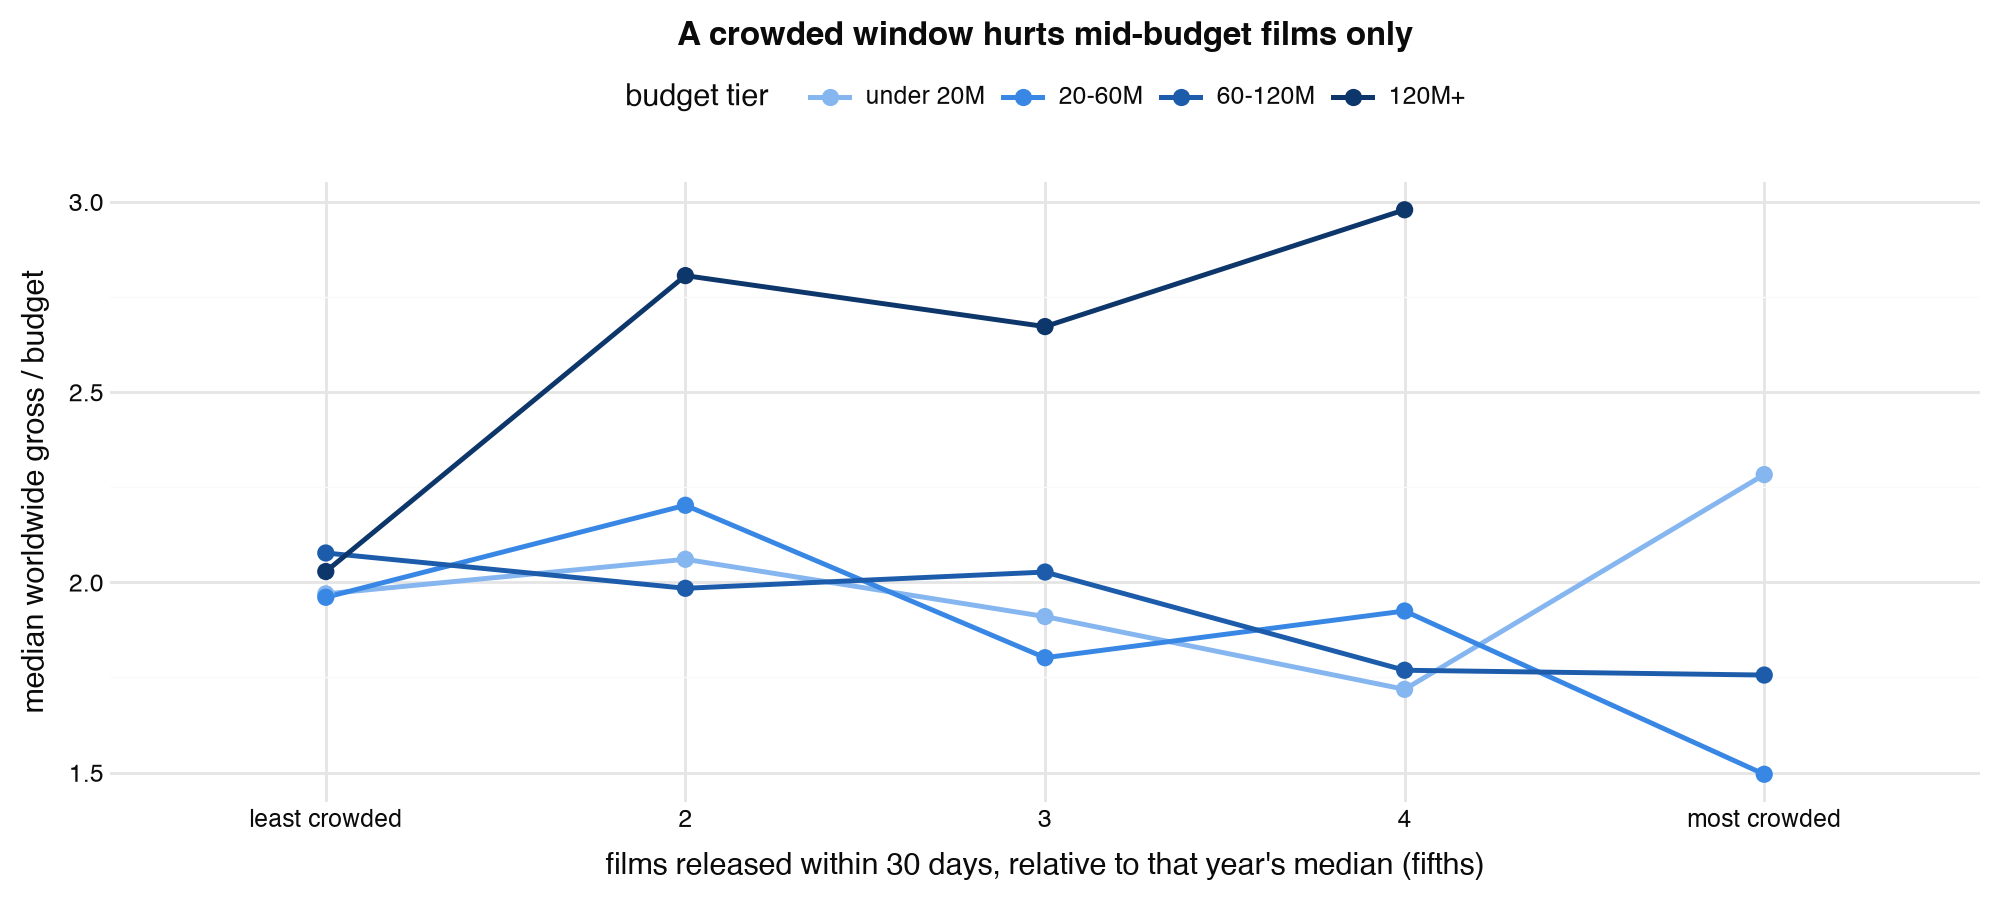

In [21]:
dev = dev.with_columns(
    crowding=pl.col("competitors") / pl.col("competitors").median().over("year")
)
crowding_fifths = ["least crowded", "2", "3", "4", "most crowded"]
by_crowding = (
    dev.with_columns(
        crowding_fifth=pl.col("crowding")
        .qcut(5, labels=crowding_fifths)
        .cast(pl.Enum(crowding_fifths))
    )
    .group_by("budget_tier", "crowding_fifth")
    .agg(
        pl.len().alias("films"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .filter(pl.col("films") >= 20)
    .sort("budget_tier", "crowding_fifth")
)

(
    ggplot(
        by_crowding,
        aes(
            "crowding_fifth",
            "median_multiple",
            color="budget_tier",
            group="budget_tier",
        ),
    )
    + geom_line(size=1)
    + geom_point(size=2.5)
    + scale_color_manual(values=TIER_COLOURS)
    + labs(
        title="A crowded window hurts mid-budget films only",
        x="films released within 30 days, relative to that year's median (fifths)",
        y="median worldwide gross / budget",
        color="budget tier",
    )
)

For films at $20-60M and $60-120M, the most crowded fifth of release dates gives a lower median multiple (1.5 and 1.8) and more flops (65% and 69%) than the least crowded fifth (2.0 and 2.1, 58% and 56% flopped). Films under $20M show no pattern, and fewer than 20 films over $120M opened in the most crowded fifth, too few to show.

H3 holds weakly and only for mid-budget films, so its effect in the model should be small.

Compare release months: median multiple and flop share.

In [22]:
dev.group_by(month=pl.col("release_date").dt.month()).agg(
    pl.len().alias("films"),
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("flop").mean().alias("flop_share"),
).sort("month")

month,films,median_multiple,flop_share
i8,u32,f64,f64
1,145,1.703,0.628
2,200,1.762,0.645
3,232,1.860,0.629
4,225,1.556,0.689
5,215,2.382,0.526
6,264,2.654,0.481
7,236,2.244,0.534
8,269,1.785,0.636
9,283,1.607,0.661


May to July and November to December give the highest median multiples (2.2 to 2.7) and the fewest flops (48% to 53%); April, September and October the lowest (about 1.6, 65% to 69% flopped).

The month is a free choice for the studio, and the gap between June and April (2.65 against 1.56) is larger than the gap between Horror and Drama (2.44 against 1.72).

### 3.6 Talent track record

H4 says a director or lead actor with a good record lowers the flop risk. A person's record uses only their films in this table released before the film in the row, so it is something the studio knew when hiring:

- `prior_films`: how many earlier films
- `prior_median_log_multiple`: the median log multiple of those films; above log(2.5) = 0.92 means their typical film broke even

Build both records and put each film in one of three groups: no earlier film in the data, a record below break-even, or a record at or above it.

In [23]:
records = prior_track_record(films, "director", prefix="director").join(
    prior_track_record(films, "actor_1", prefix="actor"), on="film_id"
)
dev = dev.join(records, on="film_id", how="left")


def record_group(prefix: str) -> pl.Expr:
    median = pl.col(f"{prefix}_prior_median_log_multiple")
    return (
        pl.when(median.is_null())
        .then(pl.lit("no earlier film"))
        .when(median < np.log(BREAK_EVEN_MULTIPLE))
        .then(pl.lit("record below break-even"))
        .otherwise(pl.lit("record at or above break-even"))
    )


talent = pl.concat(
    [
        dev.select(
            "gross_multiple",
            "flop",
            role=pl.lit("director"),
            record=record_group("director"),
        ),
        dev.select(
            "gross_multiple",
            "flop",
            role=pl.lit("lead actor"),
            record=record_group("actor"),
        ),
    ]
).with_columns(
    pl.col("record").cast(
        pl.Enum(
            [
                "no earlier film",
                "record below break-even",
                "record at or above break-even",
            ]
        )
    )
)
talent.group_by("role", "record").agg(
    pl.len().alias("films"),
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("flop").mean().alias("flop_share"),
).sort("role", "record")

role,record,films,median_multiple,flop_share
str,enum,u32,f64,f64
"""director""","""no earlier film""",1406,2.022,0.576
"""director""","""record below break-even""",711,1.721,0.661
"""director""","""record at or above break-even""",880,2.209,0.549
"""lead actor""","""no earlier film""",1188,1.942,0.577
"""lead actor""","""record below break-even""",1091,1.859,0.636
"""lead actor""","""record at or above break-even""",718,2.241,0.533


A director whose earlier films typically broke even is followed by a flop 55% of the time, against 66% for a director whose earlier films did not. For lead actors it is 53% against 64%. A director or lead new to the data sits in between, at 58%.

Plot the multiple by track-record group, for directors and lead actors side by side.

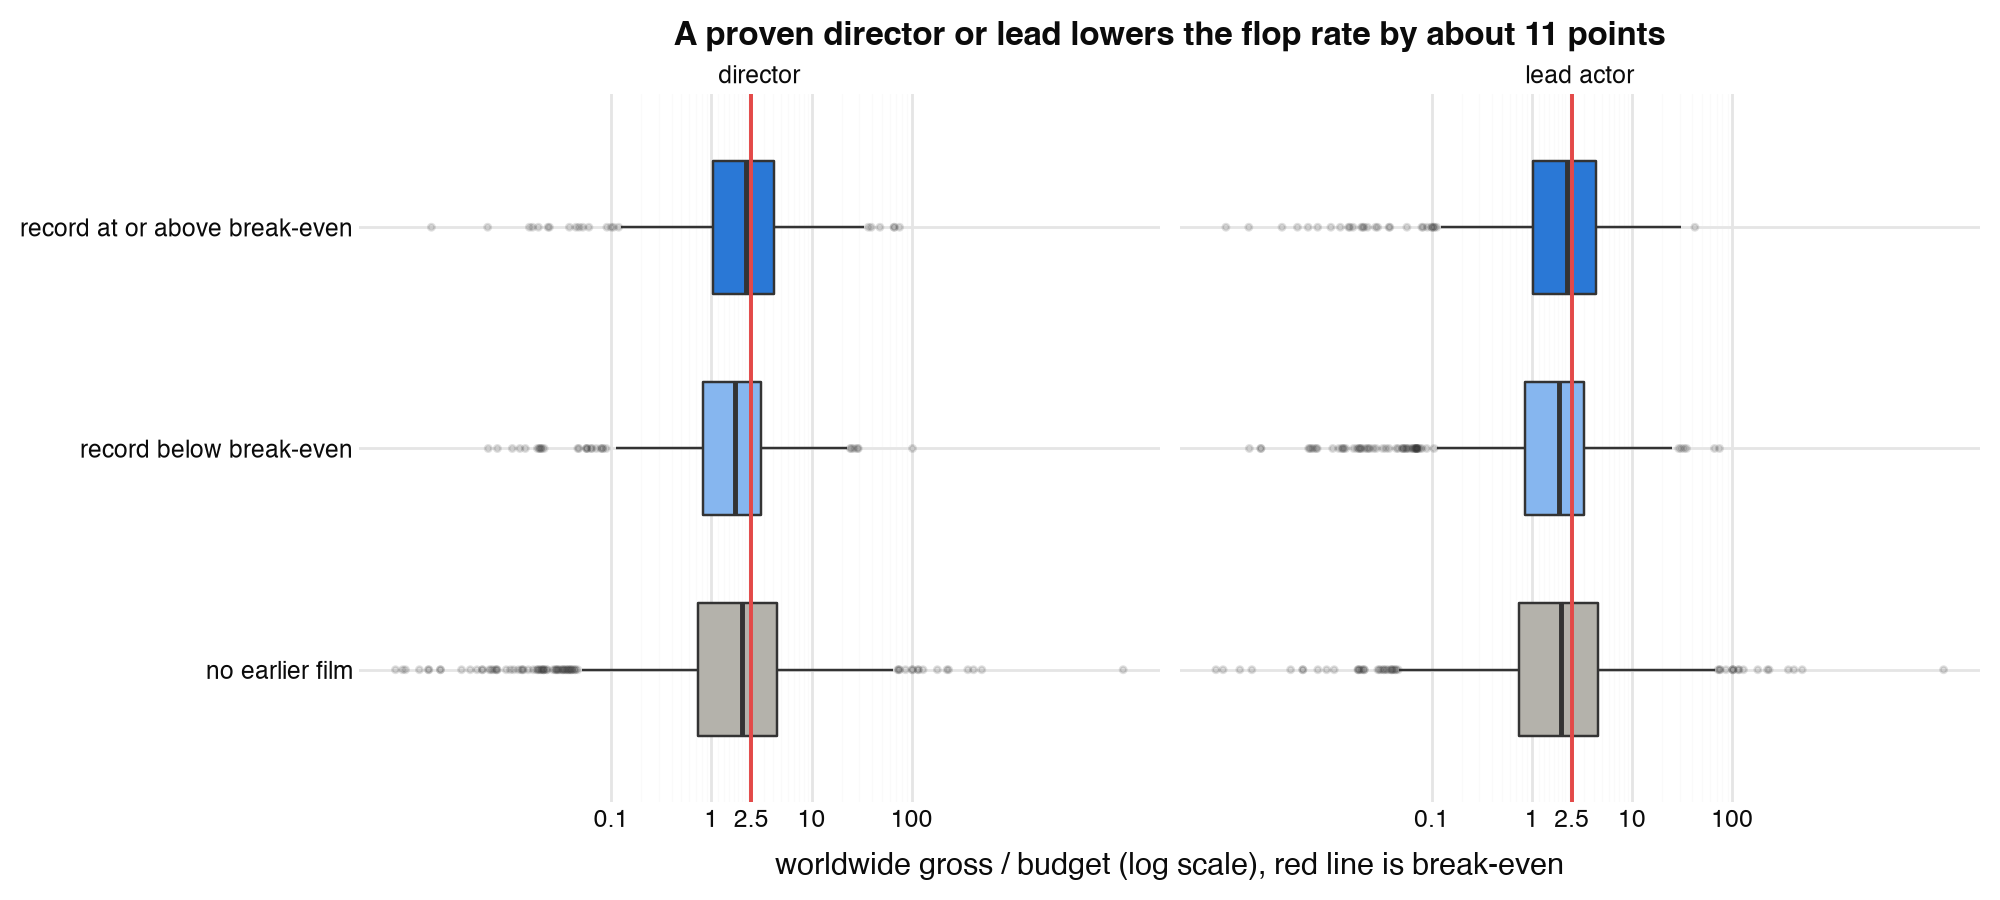

In [24]:
(
    ggplot(talent, aes("record", "gross_multiple", fill="record"))
    + geom_boxplot(outlier_alpha=0.15, outlier_size=0.8, width=0.6)
    + geom_hline(yintercept=BREAK_EVEN_MULTIPLE, color=FLOP_RED, size=0.8)
    + scale_y_log10(breaks=[0.1, 1, 2.5, 10, 100])
    + scale_fill_manual(values=[CONTEXT, TIER_COLOURS[0], ACCENT])
    + facet_wrap("role")
    + coord_flip()
    + labs(
        title="A proven director or lead lowers the flop rate by about 11 points",
        x="",
        y="worldwide gross / budget (log scale), red line is break-even",
    )
    + theme(legend_position="none")
)

The boxes overlap almost completely: a good record shifts the middle of the distribution up a little and does not narrow it.

H4 holds as a shift in the average, not as lower risk, which puts track record in the model's mean. Almost half the films have a director with no earlier film in the data, and that group has to stay in as its own level.

### 3.7 Studios

H5 says big and small studios run different strategies. Summarise each major and the independents: how much they spend, what they earn, and how wide their results spread. `log_multiple_sd` is the standard deviation of the log multiple; at 1.0, two films in three land between 0.37 and 2.7 times the studio's median multiple.

In [25]:
by_studio = (
    dev.group_by("studio")
    .agg(
        pl.len().alias("films"),
        pl.col("budget_real_musd").median().alias("median_budget_musd"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("log_multiple").std().alias("log_multiple_sd"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .with_columns(
        major=pl.when(pl.col("studio") == "Independent")
        .then(pl.lit("no"))
        .otherwise(pl.lit("yes"))
    )
    .sort("median_budget_musd", descending=True)
)
by_studio

studio,films,median_budget_musd,median_multiple,log_multiple_sd,flop_share,major
str,u32,f64,f64,f64,f64,str
"""DreamWorks""",85,78.263,2.292,0.813,0.565,"""yes"""
"""Disney""",205,60.632,2.659,1.164,0.463,"""yes"""
"""Universal""",257,50.178,2.306,1.035,0.533,"""yes"""
"""Paramount""",231,48.576,2.428,1.195,0.511,"""yes"""
"""Warner""",378,47.630,2.009,1.168,0.574,"""yes"""
"""Sony""",320,45.875,2.086,1.127,0.584,"""yes"""
"""Fox""",271,39.753,2.573,1.161,0.491,"""yes"""
"""MGM""",110,37.879,1.653,1.629,0.573,"""yes"""
"""Lionsgate""",101,22.011,2.476,1.491,0.505,"""yes"""


Plot each studio's median budget against how widely its results spread; bubble size is the number of films.

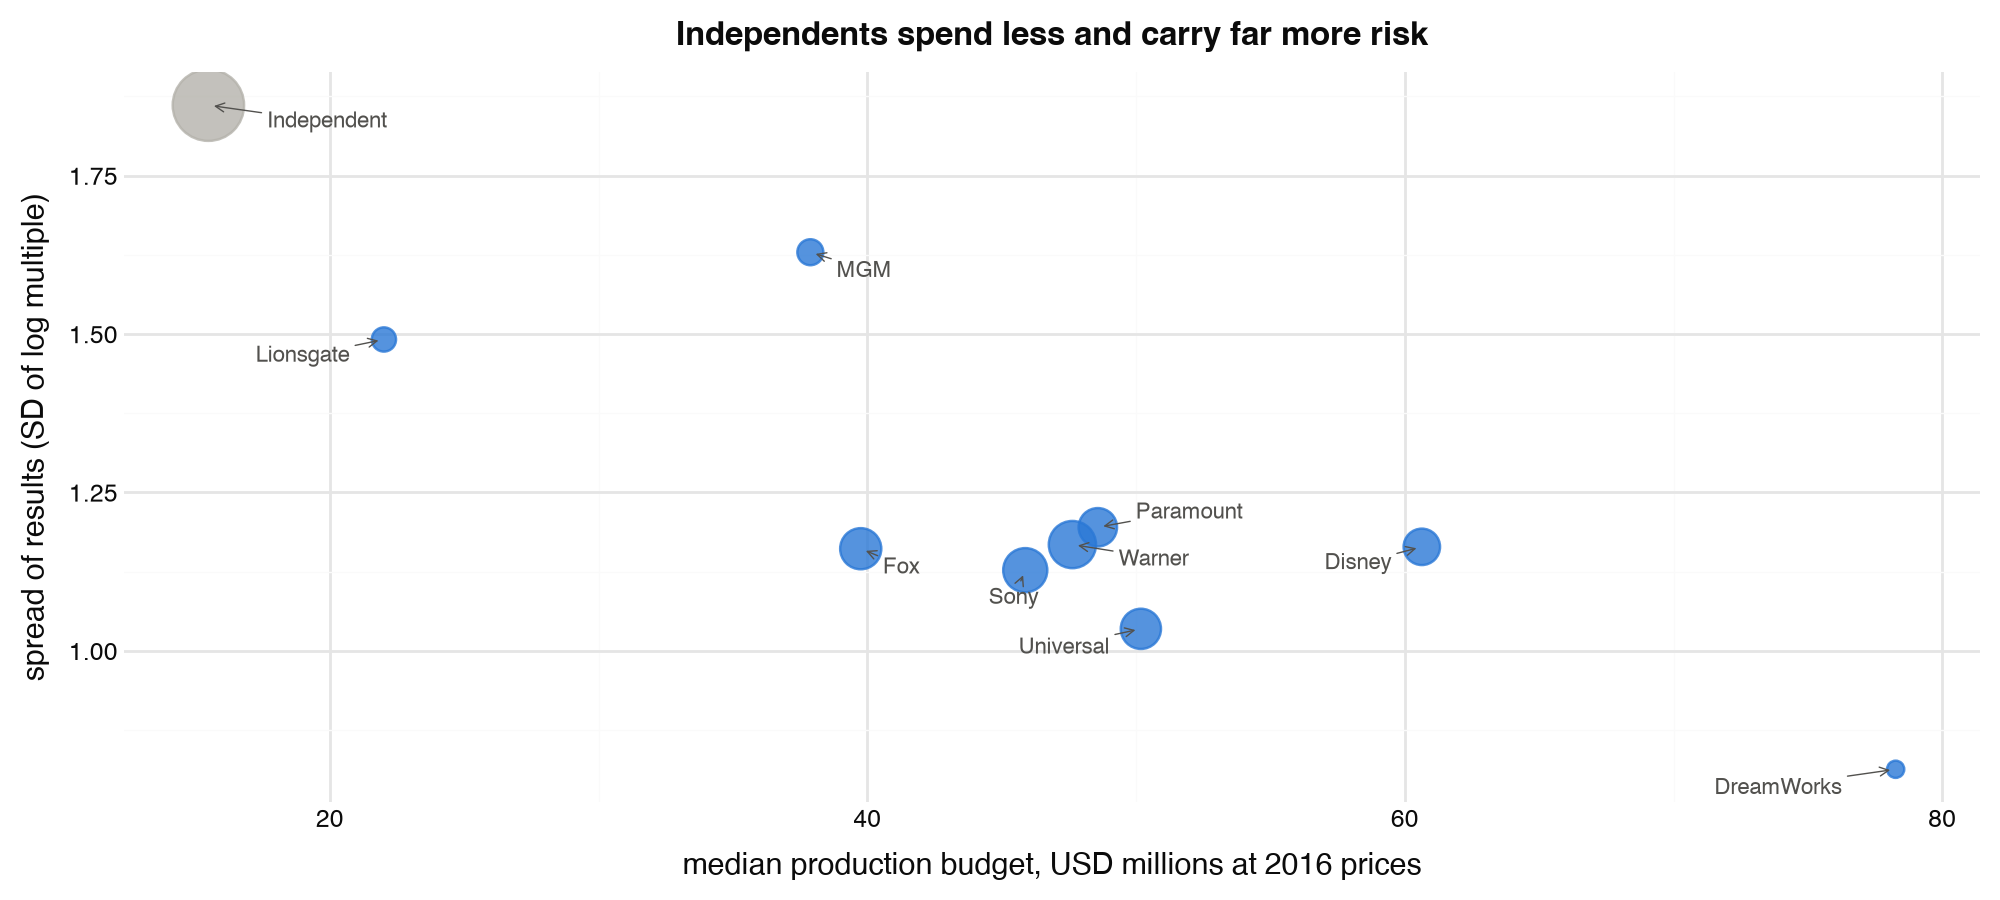

In [26]:
(
    ggplot(by_studio, aes("median_budget_musd", "log_multiple_sd"))
    + geom_point(aes(size="films", color="major"), alpha=0.8)
    + geom_text(
        aes(label="studio"), size=8, color="#52514e", adjust_text={"expand": (1.6, 1.8)}
    )
    + scale_size(range=(3, 14))
    + scale_color_manual(values={"yes": ACCENT, "no": CONTEXT})
    + labs(
        title="Independents spend less and carry far more risk",
        x="median production budget, USD millions at 2016 prices",
        y="spread of results (SD of log multiple)",
    )
    + theme(legend_position="none")
)

The majors' films return a median 1.7 to 2.7 times budget and flop 46% to 58% of the time; independents return 1.36 times and flop 69% of the time, with the widest spread (SD 1.86 against 0.81 to 1.63). Among the majors, budget and spread are barely related.

Part of the independents' risk is their small budgets (median $15M), which H1 already covers, so this table alone cannot say whether being independent adds risk on top.

### What the exploration found

Ranked by how much each finding should change the model:

1. Budget sets the risk more than the return. From the cheapest tier to the most expensive, the range of multiples narrows from 0.09-13.6 to 0.95-5.5 (10th to 90th percentile), while the median only rises from about 1.9 to 2.7. A model that gives every film the same error spread would get the flop chance wrong at both ends.
2. The early decades and the tiniest budgets are not like the rest. Films before 1980 flopped 16% of the time against 60% after, because the sources kept only the remembered ones, and 55 budgets under $1M look like errors. Both would pull any average away from what a studio faces now.
3. Release month is the largest choice after budget. Summer and holiday releases flop 48% to 53% of the time, spring and autumn releases 65% to 69%.
4. Genre shifts return and risk together, and its effect depends on the budget. Animation, family and horror do best and war, sport and history worst; romance is average. Horror's edge holds only for cheap films.
5. A proven director or lead lowers the flop rate by about 11 points, by shifting the average rather than narrowing the range.
6. Crowding matters little and only for mid-budget films, once it is measured against the year; a raw competitor count would mostly measure how completely the sources cover that year.
7. Independents flop more (69%) and spread wider than any major, partly because their budgets are small.

To keep in mind: a film counts in each of its genres, so genre shares overlap, and every number here comes from `dev`, films up to 2012.